# ML Model with expected goals

In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import warnings
from sklearn.linear_model import LinearRegression

NUM_OF_COUNTRIES = 5
NUM_OF_SEASONS = 25
NUM_OF_MATCHES = 9130
NUM_OF_MATCHES_IN_A_SEASON = 1826
SEED = 1893

np.random.seed(SEED)
warnings.filterwarnings('ignore')


In [2]:
def score_from_amount_and_diff(amount, diff):
    if diff < 0:
        home_score = (amount + diff) / 2
        away_score = home_score - diff
    else:
        home_score = away_score + diff
        away_score = (amount - diff) / 2

    # cut excess floating numbers
    if (home_score - int(home_score)) == 0 and (away_score - int(away_score)) == 0:
        home_score = int(home_score)
        away_score = int(away_score)

    return home_score, away_score


def print_formatted_pred_score(country, season, matchnumber, ht_name, at_name, ht_pred_score, at_pred_score, ht_actual_score, at_actual_score):
    print("%4s %3s %3s %20s %20s %15s | %6s" %
          (country, season, matchnumber, ht_name, at_name,
           str(ht_pred_score)[0:4] + ":" + str(at_pred_score)[0:4],
           f"{ht_actual_score}:{at_actual_score}"))

def calc_mae(y_pred, y):
    mae = 0.0
    for pred, actual_value in zip(y_pred, y):
        if type(pred) == list:
            mae += np.abs((float(pred[0]) - float(actual_value)))
        else:
            mae += np.abs((float(pred) - float(actual_value)))
    return mae / len(y)


In [3]:
df_matches = pd.read_csv('matches_xg.csv', sep=';')

df_matches["is_eng"] = df_matches["country"].apply(
    lambda x: 1 if x == "ENG" else 0)
df_matches["is_esp"] = df_matches["country"].apply(
    lambda x: 1 if x == "ESP" else 0)
df_matches["is_fra"] = df_matches["country"].apply(
    lambda x: 1 if x == "FRA" else 0)
df_matches["is_ger"] = df_matches["country"].apply(
    lambda x: 1 if x == "GER" else 0)
df_matches["is_ita"] = df_matches["country"].apply(
    lambda x: 1 if x == "ITA" else 0)

df_matches

,country,season,matchnumber,ht_name,at_name,ht_curr_eff_chancediff,at_curr_eff_chancediff,ht_past_chancediff_combined,at_past_chancediff_combined,ht_curr_eff_chanceamount,...,at_last_year_xg_amount,xg_amount,xg_diff,actual_goalamount,actual_goaldiff,is_eng,is_esp,is_fra,is_ger,is_ita
0,ENG,14,1,Queens Park Rangers,Hull,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,3.018240,0.783100,1,-1,1,0,0,0,0
1,ENG,14,1,Newcastle,Man City,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,2.446113,-0.514947,2,-2,1,0,0,0,0
2,ENG,14,1,Burnley,Chelsea,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,2.501101,-1.758819,4,-2,1,0,0,0,0
3,ENG,14,1,Arsenal,Crystal Palace,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,1.712261,1.395959,3,1,1,0,0,0,0
4,ENG,14,1,West Ham,Tottenham,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,2.870160,0.836040,1,-1,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9125,ITA,18,38,Frosinone,Chievo,-4.492426,-4.452152,-3.581579,-1.943421,-2.059192,...,0.959903,0.585014,0.537046,0,0,0,0,0,0,1
9126,ITA,18,38,Fiorentina,CFC Genoa,1.172165,-1.286395,1.539474,-1.361842,0.407509,...,1.172081,0.370430,0.221648,0,0,0,0,0,0,1
9127,ITA,18,38,Bologna,Napoli,-0.932129,5.242267,-1.497368,5.293421,-0.446689,...,1.795735,2.737759,-0.858041,5,1,0,0,0,0,1
9128,ITA,18,38,Inter,Empoli,2.881676,-3.462648,2.380263,-3.058772,1.042860,...,1.370037,4.515770,0.970270,3,1,0,0,0,0,1


## Featuresets

In [4]:
all_features = [
    "ht_curr_eff_chancediff", "at_curr_eff_chancediff",
    "ht_past_chancediff_combined", "at_past_chancediff_combined",
    "ht_curr_eff_chanceamount", "at_curr_eff_chanceamount",
    "ht_past_chanceamount", "at_past_chanceamount",
    "ht_fitness", "at_fitness",
    "ht_market_value_ln_relative", "at_market_value_ln_relative",
    "ht_curr_chancediff", "at_curr_chancediff",
    "ht_last_year_chancediff", "at_last_year_chancediff",
    "ht_curr_chanceamount", "at_curr_chanceamount",
    "ht_last_year_chanceamount", "at_last_year_chanceamount",
    "ht_market_value", "at_market_value",
    "ht_market_value_ln", "at_market_value_ln",
    "is_eng", "is_esp", "is_fra", "is_ger", "is_ita",
    "ht_curr_xg_diff", "at_curr_xg_diff", "ht_last_year_xg_diff", "at_last_year_xg_diff",
    "ht_curr_xg_amount", "at_curr_xg_amount", "ht_last_year_xg_amount", "at_last_year_xg_amount"
]

ga_xg_features = [
    "ht_curr_xg_amount", "at_curr_xg_amount", 
    "ht_last_year_xg_amount", "at_last_year_xg_amount"
]

gd_xg_features = [
    "ht_market_value_ln_relative", "at_market_value_ln_relative",
    "ht_curr_xg_diff", "at_curr_xg_diff", 
    "ht_last_year_xg_diff", "at_last_year_xg_diff"
]

ga_features_heuer = [
    "ht_curr_eff_chanceamount", "at_curr_eff_chanceamount",
    "ht_past_chanceamount", "at_past_chanceamount"
]

gd_features_heuer = [
    "ht_curr_eff_chancediff", "at_curr_eff_chancediff",
    "ht_past_chancediff_combined", "at_past_chancediff_combined",
    "ht_fitness", "at_fitness",
    "ht_market_value_ln_relative", "at_market_value_ln_relative"
]

ga_feature_selection = [
    "ht_curr_eff_chanceamount", "at_curr_eff_chanceamount",
    "ht_last_year_chanceamount", "at_last_year_chanceamount",
    "ht_market_value_ln_relative", "at_market_value_ln_relative",
    "is_eng", "is_esp", "is_fra", "is_ger", "is_ita"
]

gd_feature_selection = [
    "ht_curr_eff_chancediff", "at_curr_eff_chancediff",
    "ht_last_year_chancediff", "at_last_year_chancediff",
    "ht_market_value_ln_relative", "at_market_value_ln_relative"
]

ga_label = ["xg_amount"]
gd_label = ["xg_diff"]

ga_test_label = ["actual_goalamount"]
gd_test_label = ["actual_goaldiff"]


## Data split

In [5]:
df_training, df_testing = df_matches.query(
    f"season < 18"), df_matches.query(f"season == 18")


## Model selection

In [6]:
class GeneralModel:
    def __init__(self):
        self.model = LinearRegression()

    def fit(self, df, features, label):
        self.model.fit(df[features], df[label])

    def predict(self, df, features):
        return self.model.predict(df[features])

    def predict_single(self, row, features):
        return self.model.predict([row[features]])[0][0]

    def print_weights(self):
        print("General model weights:")
        print(self.model.coef_, self.model.intercept_)


class WeightsPerMatchnumberModel:
    def __init__(self):
        self.models = []

    def fit(self, df, features, label):
        for i in range(1, 39):
            matchnumber_df = df.query(f"matchnumber == {i}")
            self.models.append(LinearRegression().fit(matchnumber_df[features],
                                                      matchnumber_df[label]))

    def predict(self, df, features):
        preds = []
        for index, row in df.iterrows():
            preds.append(
                self.models[row["matchnumber"]-1].predict([row[features]])[0])
        return preds

    def predict_single(self, row, features):
        return self.models[row["matchnumber"]-1].predict([row[features]])[0]

    def print_weights(self):
        print("Weights per matchnum model weights:")
        for model in self.models:
            print(model.coef_, model.intercept_)


class SectionedModel:
    def __init__(self):
        self.models = [LinearRegression(), LinearRegression(),
                       LinearRegression()]

    def fit(self, df, features, label):
        first_df = df.query(
            f"(country == 'GER' and matchnumber < 18) or (country != 'GER' and matchnumber < 20)")
        second_df = df.query(
            f"(country == 'GER' and matchnumber >= 18 and matchnumber < 31) or (country != 'GER' and matchnumber >= 20 and matchnumber < 35)")
        third_df = df.query(
            f"(country == 'GER' and matchnumber >= 31) or (country != 'GER' and matchnumber >= 35)")
        if not first_df.empty:
            self.models[0].fit(first_df[features], first_df[label])
        else:
            self.models[0].fit([np.ones(len(features))], [[1]])
        if not second_df.empty:
            self.models[1].fit(second_df[features], second_df[label])
        else:
            self.models[1].fit([np.ones(len(features))], [[1]])
        if not third_df.empty:
            self.models[2].fit(third_df[features], third_df[label])
        else:
            self.models[2].fit([np.ones(len(features))], [[1]])

    def predict(self, df, features):
        preds = []
        for index, row in df.iterrows():
            if (row["country"] == "GER" and row["matchnumber"] < 18) or (row["country"] != 'GER' and row["matchnumber"] < 20):
                preds.append(self.models[0].predict([row[features]])[0])
            if (row["country"] == "GER" and row["matchnumber"] >= 18) and (row["matchnumber"] < 31) or (row["country"] != 'GER' and row["matchnumber"] >= 20 and row["matchnumber"] < 35):
                preds.append(self.models[1].predict([row[features]])[0])
            if (row["country"] == "GER" and row["matchnumber"] >= 31) or (row["country"] != 'GER' and row["matchnumber"] >= 35):
                preds.append(self.models[2].predict([row[features]])[0])
        return preds

    def predict_single(self, row, features):
        if (row["country"] == "GER" and row["matchnumber"] < 18) or (row["country"] != 'GER' and row["matchnumber"] < 20):
            return self.models[0].predict([row[features]])[0][0]
        if (row["country"] == "GER" and row["matchnumber"] >= 18) and (row["matchnumber"] < 31) or (row["country"] != 'GER' and row["matchnumber"] >= 20 and row["matchnumber"] < 35):
            return self.models[1].predict([row[features]])[0][0]
        if (row["country"] == "GER" and row["matchnumber"] >= 31) or (row["country"] != 'GER' and row["matchnumber"] >= 35):
            return self.models[2].predict([row[features]])[0][0]

    def print_weights(self):
        print("Sectioned model weights:")
        for model in self.models:
            print(model.coef_, model.intercept_)


## K-Fold-Crossvalidation

In [7]:

do_crossvalidation = False

if do_crossvalidation:
    for feature_set_name, feature_set in zip(["all", "heuer", "final_selection", "xg_features"], [(all_features, all_features), (ga_features_heuer, gd_features_heuer), (ga_feature_selection, gd_feature_selection), (ga_xg_features, gd_xg_features)]):
        for weight_set_name in ["general", "per_match_no", "sectioned"]:
            xga_validation_error, xgd_validation_error = 0, 0
            ga_validation_error, gd_validation_error = 0, 0
            for season in range(14,18):
                train_data, valid_data = df_training.query(
                    f"season != {season}"), df_training.query(f"season == {season}")

                if weight_set_name == "general":
                    ga_model, gd_model = GeneralModel(), GeneralModel()
                    ga_model.fit(
                        train_data, feature_set[0], ga_label)
                    gd_model.fit(
                        train_data, feature_set[1], gd_label)
                if weight_set_name == "per_match_no":
                    ga_model, gd_model = WeightsPerMatchnumberModel(), WeightsPerMatchnumberModel()
                    ga_model.fit(
                        train_data, feature_set[0], ga_label)
                    gd_model.fit(
                        train_data, feature_set[1], gd_label)
                if weight_set_name == "sectioned":
                    ga_model, gd_model = SectionedModel(), SectionedModel()
                    ga_model.fit(
                        train_data, feature_set[0], ga_label)
                    gd_model.fit(
                        train_data, feature_set[1], gd_label)
                
                ga_preds = ga_model.predict(
                    valid_data, feature_set[0])
                gd_preds = gd_model.predict(
                    valid_data, feature_set[1])
                xga_validation_error += (calc_mae(ga_preds, valid_data[ga_label].values)) * 0.25
                xgd_validation_error += (calc_mae(gd_preds,
                                                    valid_data[gd_label].values)) * 0.25
                ga_validation_error += (calc_mae(ga_preds,
                                                    valid_data[ga_test_label].values)) * 0.25
                gd_validation_error += (calc_mae(gd_preds,
                                                    valid_data[gd_test_label].values)) * 0.25
                

            print("%-16s %-12s " %
                (feature_set_name, weight_set_name))
            print("xga validation error:", xga_validation_error)
            print("xgd validation error:", xgd_validation_error)
            print("ga validation error:", ga_validation_error)
            print("gd validation error:", gd_validation_error, end="\n\n")


#  final_selection  sectioned
# xga validation error: 0.8323362513260881
# ga validation error: 1.320790234683054

#  final_selection  general
# xgd validation error: 0.8128795609437992
# gd validation error: 1.2407327920523523


## Final models

In [8]:
ga_model = SectionedModel()
gd_model = SectionedModel()

ga_model.fit(df_training, ga_feature_selection, ga_label)
gd_model.fit(df_training,
              gd_feature_selection, gd_label)


print("Generalizazion error xga:", calc_mae(ga_model.predict(
    df_testing, ga_feature_selection), df_testing[ga_label].values))
print("Generalizazion error xgd:", calc_mae(gd_model.predict(
    df_testing, gd_feature_selection), df_testing[gd_label].values))
print("------")
print("Generalizazion error ga :", calc_mae(ga_model.predict(
    df_testing, ga_feature_selection), df_testing[ga_test_label].values))
print("Generalizazion error gd :", calc_mae(gd_model.predict(
    df_testing, gd_feature_selection), df_testing[gd_test_label].values))

print("--------")
ga_model.print_weights()
print("--------")
gd_model.print_weights()


Generalizazion error xga: 0.8398924092350106
Generalizazion error xgd: 0.8498980920539219
------
Generalizazion error ga : 1.3113518165356275
Generalizazion error gd : 1.23591685750024
--------
Sectioned model weights:
[[ 0.02453106  0.03325307  0.04405289 -0.02248013  0.16637564  0.05173165
   0.00868337  0.0039972  -0.16636622  0.16243635 -0.0087507 ]] [2.48134519]
[[ 0.12172989  0.0746941   0.00243882  0.01546661 -0.03803714 -0.10377818
  -0.0345782   0.11941246 -0.12083272  0.03682208 -0.00082362]] [2.50118841]
[[ 0.13005905  0.02586838 -0.01756136  0.02222757  0.0170349   0.06722803
  -0.11071402  0.02303177 -0.05934615  0.06533046  0.08169794]] [2.79343768]
--------
Sectioned model weights:
[[ 0.04663693 -0.04396121  0.04180226 -0.03399329  0.46251419 -0.4320935 ]] [0.35857329]
[[ 1.44765517e-01 -1.04377635e-01 -2.27213573e-02  6.15972281e-05
   1.88618186e-01 -3.15727229e-01]] [0.39772622]
[[ 0.11644687 -0.12536687  0.00636167 -0.02174056  0.19581446 -0.16793557]] [0.36348181]


## Generate training error csv

In [9]:
do_a_training_error_run = False

if do_a_training_error_run:
      training_error_data = dict()
      xga_abs_training_error, xgd_abs_training_error = 0,0
      ga_abs_training_error, gd_abs_training_error = 0,0
      prev_matchnumber = 0

      for index, row in df_training.iterrows():
            if row["season"] == 14 and row["matchnumber"] == 1:
                  ga_pred, gd_pred = 0,0
            else:
                  if int(row["matchnumber"]) > prev_matchnumber:
                        curr_training_data_df = df_training.query(
                            f"season < {row['season']} or (season == {row['season']} and matchnumber < {row['matchnumber']})")
                        ga_model = SectionedModel()
                        gd_model = SectionedModel()
                        ga_model.fit(curr_training_data_df,
                                     ga_feature_selection, ga_label)
                        gd_model.fit(curr_training_data_df,
                                     gd_feature_selection, gd_label)

                  ga_pred = ga_model.predict_single(
                      row, ga_feature_selection)
                  gd_pred = gd_model.predict_single(
                      row, gd_feature_selection)

            xga_abs_training_error += np.abs(
                  ga_pred - float(row[ga_label]))
            xgd_abs_training_error += np.abs(
                gd_pred - float(row[gd_label]))
            ga_abs_training_error += np.abs(
                ga_pred - float(row[ga_test_label]))
            gd_abs_training_error += np.abs(
                gd_pred - float(row[gd_test_label]))
            
            if row["country"] not in training_error_data.keys():
                  training_error_data[row["country"]] = {}
            if row["season"] not in training_error_data[row["country"]].keys():
                  training_error_data[row["country"]][row["season"]] = {}
            if row["matchnumber"] not in training_error_data[row["country"]][row["season"]].keys():
                  training_error_data[row["country"]
                                          ][row["season"]][row["matchnumber"]] = {"abs_error_ga": 0, "abs_error_gd": 0, "abs_error_xga": 0, "abs_error_xgd": 0}
            if row["country"] == "GER":
                  training_error_data[row["country"]
                                      ][row["season"]][row["matchnumber"]]["abs_error_ga"] += float(np.abs(ga_pred - row[ga_test_label]) / 9)
                  training_error_data[row["country"]
                                      ][row["season"]][row["matchnumber"]]["abs_error_gd"] += float(np.abs(gd_pred - row[gd_test_label]) / 9)
                  training_error_data[row["country"]
                                          ][row["season"]][row["matchnumber"]]["abs_error_xga"] += float(np.abs(ga_pred - row[ga_label]) / 9)
                  training_error_data[row["country"]
                                      ][row["season"]][row["matchnumber"]]["abs_error_xgd"] += float(np.abs(gd_pred - row[gd_label]) / 9)
            else:
                  training_error_data[row["country"]
                                      ][row["season"]][row["matchnumber"]]["abs_error_ga"] += float(np.abs(ga_pred - row[ga_test_label]) / 10)
                  training_error_data[row["country"]
                                      ][row["season"]][row["matchnumber"]]["abs_error_gd"] += float(np.abs(gd_pred - row[gd_test_label]) / 10)
                  training_error_data[row["country"]
                                      ][row["season"]][row["matchnumber"]]["abs_error_xga"] += float(np.abs(ga_pred - row[ga_label]) / 10)
                  training_error_data[row["country"]
                                      ][row["season"]][row["matchnumber"]]["abs_error_xgd"] += float(np.abs(gd_pred - row[gd_label]) / 10)

      print("Training MAE xga:",
            xga_abs_training_error / (df_training.shape[0]))
      print("Training MAE xgd:", xgd_abs_training_error /
            (df_training.shape[0]))
      print("Training MAE ga :",
            ga_abs_training_error / (df_training.shape[0]))
      print("Training MAE gd :", gd_abs_training_error /
            (df_training.shape[0]))


In [10]:
if do_a_training_error_run:
      print("country;season_matchnumber;abs_error_ga;abs_error_gd;abs_error_xga;abs_error_xgd")
      for a in training_error_data.keys():
            for b in training_error_data[a].keys():
                  for c in training_error_data[a][b].keys():
                        print(a+";"+str(b)+"_"+str(c)+";" +
                              str(training_error_data[a][b][c]["abs_error_ga"])+";"+str(training_error_data[a][b][c]["abs_error_gd"])+";" +
                              str(training_error_data[a][b][c]["abs_error_xga"])+";"+str(training_error_data[a][b][c]["abs_error_xgd"]))


## Plot training error

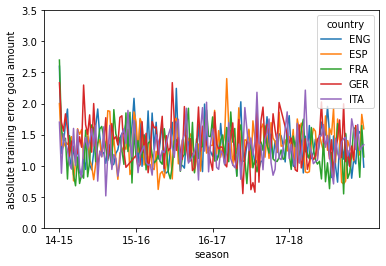

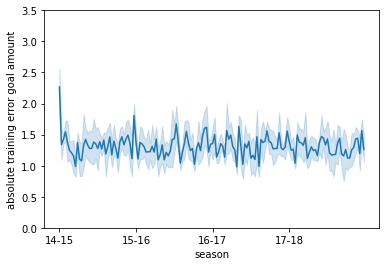

In [11]:
training_error_df = pd.read_csv('training_error.csv', sep=';')
sns.lineplot(data=training_error_df,
             x="season_matchnumber", y="abs_error_ga", hue="country")
plt.xticks(["14_1", "15_1", "16_1", "17_1"], [
           "14-15", "15-16", "16-17", "17-18"])
plt.ylim(0, 3.5)
plt.xlabel("season")
plt.ylabel("absolute training error goal amount")
plt.show()
sns.lineplot(data=training_error_df, x="season_matchnumber",
             y="abs_error_ga")
plt.xticks(["14_1", "15_1", "16_1", "17_1"], [
           "14-15", "15-16", "16-17", "17-18"])
plt.ylim(0, 3.5)
plt.xlabel("season")
plt.ylabel("absolute training error goal amount")
plt.show()


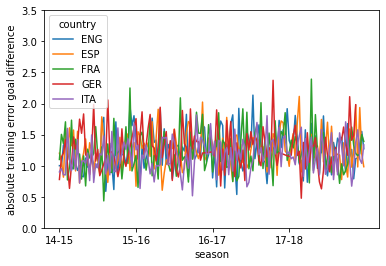

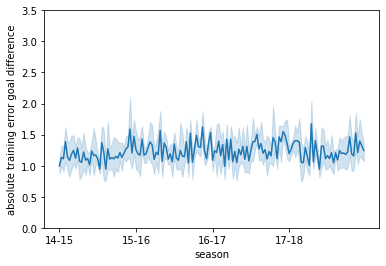

In [12]:
sns.lineplot(data=training_error_df, x="season_matchnumber",
             y="abs_error_gd", hue="country")
plt.xticks(["14_1", "15_1", "16_1", "17_1"], [
           "14-15", "15-16", "16-17", "17-18"])
plt.ylim(0, 3.5)
plt.xlabel("season")
plt.ylabel("absolute training error goal difference")
plt.show()
sns.lineplot(data=training_error_df, x="season_matchnumber",
             y="abs_error_gd")
plt.xticks(["14_1", "15_1", "16_1", "17_1"], [
           "14-15", "15-16", "16-17", "17-18"])
plt.ylim(0, 3.5)
plt.xlabel("season")
plt.ylabel("absolute training error goal difference")
plt.show()


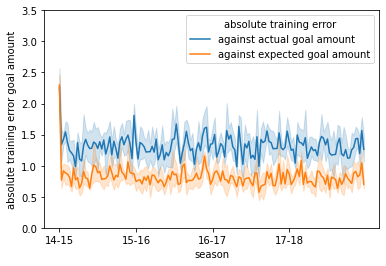

In [13]:
training_error_df["against actual goal amount"] = training_error_df["abs_error_ga"]
training_error_df["against expected goal amount"] = training_error_df["abs_error_xga"]
melted_df = training_error_df[["season_matchnumber", "against actual goal amount", "against expected goal amount"]].melt(
    "season_matchnumber", var_name="absolute training error", value_name="vals")

sns.lineplot(data=melted_df, x="season_matchnumber",
             y="vals", hue="absolute training error")
plt.xticks(["14_1", "15_1", "16_1", "17_1"], [
           "14-15", "15-16", "16-17", "17-18"])
plt.xlabel("season")
plt.ylabel("absolute training error goal amount")
plt.ylim(0, 3.5)
plt.show()


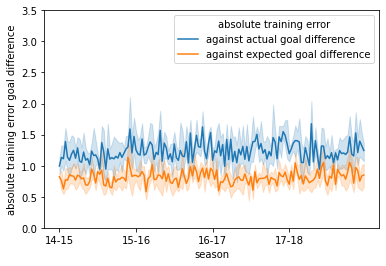

In [14]:
training_error_df["against actual goal difference"] = training_error_df["abs_error_gd"]
training_error_df["against expected goal difference"] = training_error_df["abs_error_xgd"]
melted_df = training_error_df[["season_matchnumber", "against actual goal difference", "against expected goal difference"]].melt(
    "season_matchnumber", var_name="absolute training error", value_name="vals")

sns.lineplot(data=melted_df, x="season_matchnumber",
             y="vals", hue="absolute training error")
plt.xticks(["14_1", "15_1", "16_1", "17_1"], [
           "14-15", "15-16", "16-17", "17-18"])
plt.xlabel("season")
plt.ylabel("absolute training error goal difference")
plt.ylim(0, 3.5)
plt.show()


## prediction distribution

621


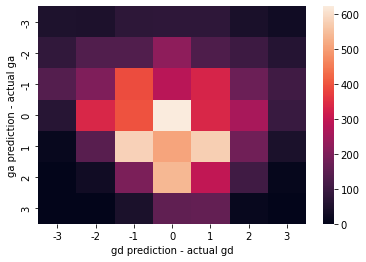

In [16]:
ga_abs_error, gd_abs_error = [], []

ga_preds = ga_model.predict(df_matches, ga_feature_selection)
gd_preds = gd_model.predict(df_matches, gd_feature_selection)

for ga_pred, gd_pred, ga_actual, gd_actual in zip(ga_preds, gd_preds, df_matches["actual_goalamount"].values, df_matches["actual_goaldiff"].values):
        ga_abs_error.append(round(ga_pred[0]-ga_actual))
        gd_abs_error.append(round(gd_pred[0]-gd_actual))


data = dict()
for x in range(-10, 10):
        data[x] = {}
        for y in range(-10, 10):
                data[x][y] = 0

for ga, gd in zip(ga_abs_error, gd_abs_error):
        data[ga][gd] += 1

sorted_keys = list(data.keys())
sorted_keys.sort()

ga, gd, count = [], [], []

for key in sorted_keys:
        for x in data[key].keys():
                if key < 4 and key > -4 and x < 4 and x > -4:
                        ga.append(key)
                        gd.append(x)
                        count.append(data[key][x])

heatmap_df = pd.DataFrame()
heatmap_df["ga prediction - actual ga"] = ga
heatmap_df["gd prediction - actual gd"] = gd
heatmap_df["count"] = count


heatmap_df = heatmap_df.pivot(
    "ga prediction - actual ga", "gd prediction - actual gd", "count")

sns.heatmap(heatmap_df)
plt.show()
